Setup complete.
Dataset used : 20 Newsgroups (5-class subset)
Documents    : 4847 | Classes: ['graphics', 'forsale', 'hockey', 'med', 'guns']
Example doc  :   One more reason for men to learn the Lamaze breathing techniques, in order to be able to get some pain reduction instantly, wherever you are. ...


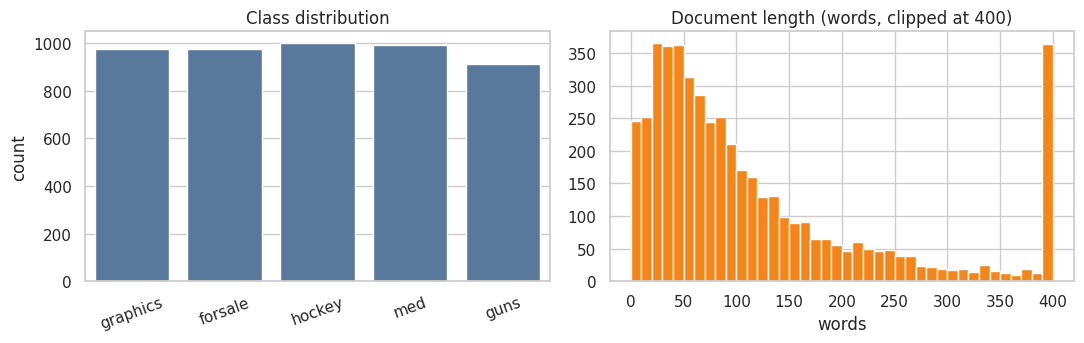

Median length: 79 words | Mean: 176
Train / test docs : 3635 / 1212
TF-IDF features   : 83748 (sparsity 99.8%)
SVD explained var : 10.73% with 100 components
Logistic Regression          acc=0.9026  macro-F1=0.9026  fit= 10.29s
Multinomial NB               acc=0.9068  macro-F1=0.9070  fit=  0.02s
Linear SVM                   acc=0.9134  macro-F1=0.9134  fit=  0.39s
Decision Tree (single)       acc=0.7814  macro-F1=0.7811  fit=  0.73s
Random Forest (TF-IDF)       acc=0.8482  macro-F1=0.8502  fit= 30.20s
Random Forest (SVD)          acc=0.8515  macro-F1=0.8524  fit=  7.28s
Bagged Logistic Reg.         acc=0.9002  macro-F1=0.9003  fit=145.36s
Bagged Decision Trees        acc=0.8350  macro-F1=0.8362  fit= 45.13s
AdaBoost (stumps, SVD)       acc=0.8408  macro-F1=0.8418  fit= 33.09s
Hist. Gradient Boosting (SVD) acc=0.8663  macro-F1=0.8668  fit=  4.75s
Voting (hard)                acc=0.9101  macro-F1=0.9101  fit= 11.40s
Voting (soft)                acc=0.9109  macro-F1=0.9109  fit= 11.15s
S

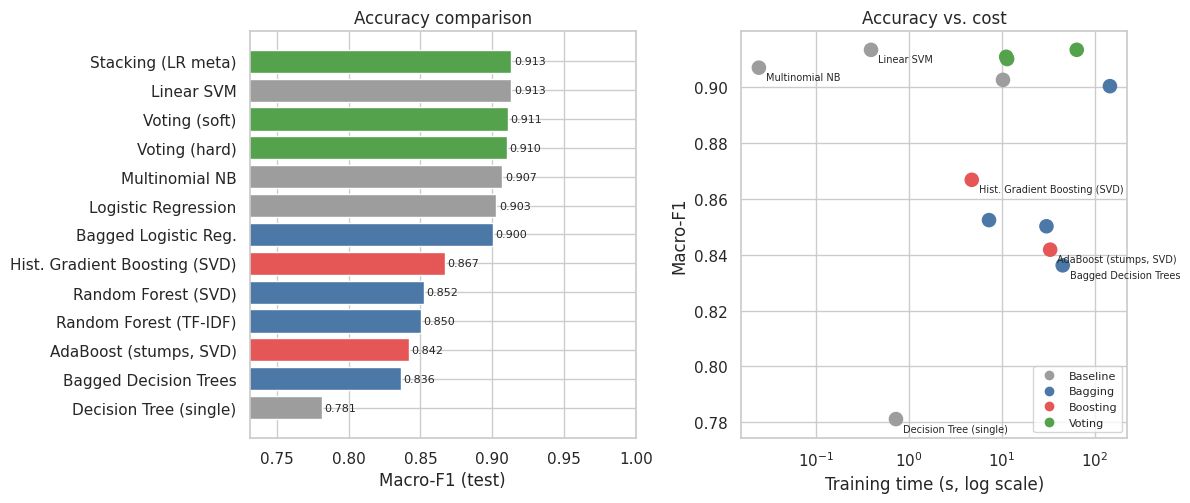

Best model: Stacking (LR meta)
              precision    recall  f1-score   support

    graphics      0.939     0.885     0.911       243
     forsale      0.953     0.918     0.935       244
      hockey      0.866     0.956     0.909       250
         med      0.914     0.903     0.909       248
        guns      0.903     0.903     0.903       227

    accuracy                          0.913      1212
   macro avg      0.915     0.913     0.913      1212
weighted avg      0.915     0.913     0.913      1212



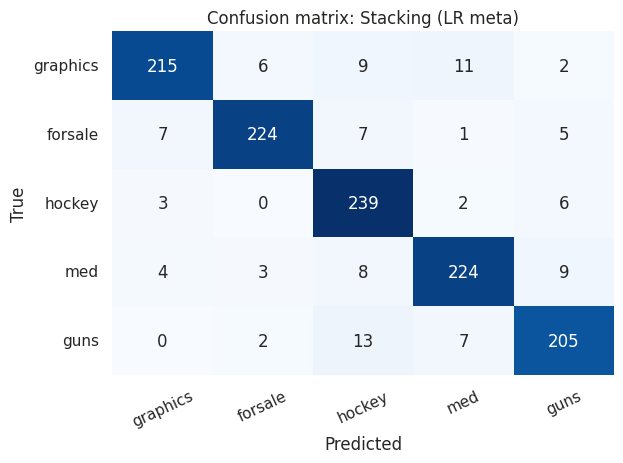

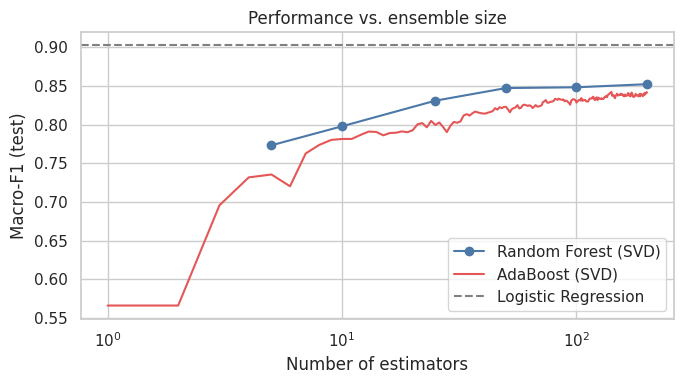

Voting (soft)                    minus Logistic Regression : +0.0085  95% CI [+0.0010, +0.0160]  -> significant
Stacking (LR meta)               minus Logistic Regression : +0.0107  95% CI [+0.0029, +0.0194]  -> significant
Random Forest (TF-IDF)           minus Logistic Regression : -0.0531  95% CI [-0.0721, -0.0353]  -> significant
Hist. Gradient Boosting (SVD)    minus Logistic Regression : -0.0364  95% CI [-0.0518, -0.0222]  -> significant


In [1]:
# %% [markdown]
# # Ensemble Learning for Text Classification
# ### Bagging, Boosting and Voting: a comparative study
#
# **Term Project**  |  Student: ______________  |  Roll No.: ______________
#
# This notebook surveys three families of ensemble methods and evaluates them on a multi-class text-classification task:
#
# | Family | Idea | Methods used here |
# |---|---|---|
# | Bagging | Train many models on bootstrap samples, then average (reduces variance) | Random Forest, Bagged Logistic Regression |
# | Boosting | Train models sequentially, each focusing on earlier mistakes (reduces bias) | AdaBoost, Histogram Gradient Boosting |
# | Voting / Stacking | Combine *different* models (adds diversity) | Hard voting, Soft voting, Stacking |
#
# **Pipeline:** load data -> TF-IDF -> baselines -> ensembles -> compare macro-F1 and training time -> error analysis.

# %% Cell 1
import time, warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("Setup complete.")

# %% [markdown]
# ## 1. Data
# The notebook first tries to load a 5-class subset of the **20 Newsgroups** corpus (headers, footers and quotes removed so models cannot cheat on metadata).
# If the corpus cannot be downloaded (for example, no internet), it falls back to a **synthetic 5-topic corpus** with realistic difficulty: shared vocabulary, a long tail of rare tokens, topic overlap and 4% label noise. The cell below prints which source was used.

# %% Cell 2
CLASSES = ["sports", "technology", "health", "finance", "politics"]

def make_synthetic_corpus(n_per_class=600, seed=SEED):
    rng = np.random.default_rng(seed)
    topic = {
      "sports": "game team season player coach league score win match goal training stadium champion fans tournament defense injury referee playoff record".split(),
      "technology": "software data network system algorithm device cloud server chip code users platform security update model internet processor app digital engineer open".split(),
      "health": "patient doctor hospital treatment disease symptoms medicine clinical diet risk therapy blood study care health surgery vaccine recovery nutrition infection dose".split(),
      "finance": "market stock bank investors profit economy shares rate fund trade growth price inflation budget earnings credit loan revenue asset dollar quarter".split(),
      "politics": "government election vote policy senate president law congress party campaign minister bill court tax debate reform voters public state leader".split(),
    }
    common = ("the of and to in is that for it with as was on be at by this have from or one had not but what all were when we there can an your which "
              "their said if do will each about how up out them then she many some so these would other into has more her two like him see time could no make "
              "than first been its who now people my made over did down only way find use may water long little very after words called just where most know").split()
    syll = ["ka","lo","mi","ra","ten","vo","sa","nu","pe","dor","qui","bel","zan","tor","mar","fi","gro","lin","pa","shu"]
    rare = ["".join(rng.choice(syll, size=rng.integers(2, 4))) for _ in range(1800)]
    rare = list(dict.fromkeys(rare))
    R = len(rare)
    aff = {}
    for c in CLASSES:
        w = rng.permutation(R).astype(float)
        w = 1.0 / (1.0 + w) ** 0.9
        w = 0.22 * w / w.sum() + 0.78 / R          # mostly uniform, mildly class-skewed
        aff[c] = w / w.sum()
    partner = {"finance": "politics", "politics": "finance", "technology": "finance",
               "health": "technology", "sports": "politics"}
    docs, labels = [], []
    for ci, c in enumerate(CLASSES):
        tw = topic[c]; zipf = 1.0 / np.arange(1, len(tw) + 1); zipf /= zipf.sum()
        for _ in range(n_per_class):
            L = int(np.clip(rng.lognormal(3.7, 0.5), 12, 200))
            toks = []
            for _ in range(L):
                u = rng.random()
                if u < 0.075:  toks.append(rng.choice(tw, p=zipf))
                elif u < 0.150:
                    other = partner[c] if rng.random() < 0.5 else rng.choice([k for k in CLASSES if k != c])
                    ow = topic[other]; toks.append(rng.choice(ow))
                elif u < 0.55: toks.append(rng.choice(common))
                else:          toks.append(rare[rng.choice(R, p=aff[c])])
            docs.append(" ".join(toks)); labels.append(ci)
    y = np.array(labels)
    flip = rng.random(len(y)) < 0.04                     # label noise
    y[flip] = rng.integers(0, len(CLASSES), flip.sum())
    idx = rng.permutation(len(y))
    return [docs[i] for i in idx], y[idx]

try:
    from sklearn.datasets import fetch_20newsgroups
    cats = ["rec.sport.hockey", "comp.graphics", "sci.med", "misc.forsale", "talk.politics.guns"]
    d = fetch_20newsgroups(subset="all", categories=cats, remove=("headers", "footers", "quotes"),
                           random_state=SEED, shuffle=True)
    texts, y = d.data, np.array(d.target)
    CLASSES = [c.split(".")[-1] for c in d.target_names]
    DATASET = "20 Newsgroups (5-class subset)"
except Exception as e:
    texts, y = make_synthetic_corpus()
    DATASET = "Synthetic 5-topic corpus (offline fallback)"

print("Dataset used :", DATASET)
print("Documents    :", len(texts), "| Classes:", CLASSES)
print("Example doc  :", texts[0][:160].replace("\n", " "), "...")

# %% Cell 3
lengths = np.array([len(t.split()) for t in texts])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(x=[CLASSES[i] for i in y], order=CLASSES, ax=ax[0], color="#4C78A8")
ax[0].set_title("Class distribution"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=20)
ax[1].hist(np.clip(lengths, 0, 400), bins=40, color="#F58518")
ax[1].set_title("Document length (words, clipped at 400)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()
print(f"Median length: {np.median(lengths):.0f} words | Mean: {lengths.mean():.0f}")

# %% [markdown]
# ## 2. Features and split
# Documents are converted to **TF-IDF** vectors (unigrams + bigrams, sublinear TF). Linear models, Naive Bayes and Random Forest use the sparse matrix directly. Boosted trees (AdaBoost and gradient boosting) need dense input, so they use a **100-dimensional Truncated SVD (LSA)** projection of the same TF-IDF matrix.

# %% Cell 4
X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(texts, y, test_size=0.25, stratify=y, random_state=SEED)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_tr_txt)
Xte = tfidf.transform(X_te_txt)

svd = TruncatedSVD(n_components=100, random_state=SEED)
Ztr = svd.fit_transform(Xtr)
Zte = svd.transform(Xte)

print("Train / test docs :", Xtr.shape[0], "/", Xte.shape[0])
print("TF-IDF features   :", Xtr.shape[1], f"(sparsity {100*(1-Xtr.nnz/np.prod(Xtr.shape)):.1f}%)")
print("SVD explained var :", f"{svd.explained_variance_ratio_.sum():.2%} with 100 components")

# %% Cell 5
RESULTS = []
PREDS = {}

def evaluate(name, family, model, Xa, Xb):
    t0 = time.perf_counter(); model.fit(Xa, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xb); pred_s = time.perf_counter() - t0
    row = dict(Model=name, Family=family,
               Accuracy=accuracy_score(y_te, pred),
               MacroF1=f1_score(y_te, pred, average="macro"),
               Fit_s=fit_s, Predict_s=pred_s)
    RESULTS.append(row); PREDS[name] = pred
    print(f"{name:<28s} acc={row['Accuracy']:.4f}  macro-F1={row['MacroF1']:.4f}  fit={fit_s:6.2f}s")
    return model

# %% [markdown]
# ## 3. Single-model baselines

# %% Cell 6
lr  = evaluate("Logistic Regression", "Baseline", LogisticRegression(C=10, max_iter=2000), Xtr, Xte)
nb  = evaluate("Multinomial NB", "Baseline", MultinomialNB(alpha=0.1), Xtr, Xte)
svm = evaluate("Linear SVM", "Baseline", LinearSVC(C=1.0), Xtr, Xte)
dt  = evaluate("Decision Tree (single)", "Baseline", DecisionTreeClassifier(max_depth=None, random_state=SEED), Ztr, Zte)

# %% [markdown]
# ## 4. Bagging
# **Random Forest** adds feature subsampling to bootstrap aggregation. **Bagged Logistic Regression** tests the textbook claim that bagging helps *unstable* learners much more than *stable* ones.

# %% Cell 7
rf = evaluate("Random Forest (TF-IDF)", "Bagging",
              RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=-1, random_state=SEED), Xtr, Xte)
rf_svd = evaluate("Random Forest (SVD)", "Bagging",
              RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), Ztr, Zte)
bag_lr = evaluate("Bagged Logistic Reg.", "Bagging",
              BaggingClassifier(LogisticRegression(C=10, max_iter=1000), n_estimators=15, random_state=SEED), Xtr, Xte)
bag_dt = evaluate("Bagged Decision Trees", "Bagging",
              BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=SEED), Ztr, Zte)

# %% [markdown]
# ## 5. Boosting
# **AdaBoost (multi-class SAMME)** reweights misclassified documents. **Histogram gradient boosting** fits trees to the gradient of the loss. (LightGBM/XGBoost behave similarly; scikit-learn's implementation is used so the notebook has no extra dependencies.)

# %% Cell 8
ada = evaluate("AdaBoost (stumps, SVD)", "Boosting",
               AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.5,
                                  random_state=SEED), Ztr, Zte)
hgb = evaluate("Hist. Gradient Boosting (SVD)", "Boosting",
               HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_depth=4, random_state=SEED), Ztr, Zte)

# %% [markdown]
# ## 6. Voting and stacking
# Base models: Logistic Regression, Naive Bayes and a *calibrated* Linear SVM (calibration gives `predict_proba`, needed for soft voting). **Hard voting** takes the majority label; **soft voting** averages probabilities; **stacking** learns a meta-classifier on cross-validated base predictions.

# %% Cell 9
def base_models():
    return [("lr", LogisticRegression(C=10, max_iter=2000)),
            ("nb", MultinomialNB(alpha=0.1)),
            ("svm", CalibratedClassifierCV(LinearSVC(C=1.0), cv=3))]

hard = evaluate("Voting (hard)", "Voting", VotingClassifier(base_models(), voting="hard"), Xtr, Xte)
soft = evaluate("Voting (soft)", "Voting", VotingClassifier(base_models(), voting="soft"), Xtr, Xte)
stack = evaluate("Stacking (LR meta)", "Voting",
                 StackingClassifier(base_models(), final_estimator=LogisticRegression(max_iter=1000),
                                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED)), Xtr, Xte)

# %% [markdown]
# ## 7. Results

# %% Cell 10
res = pd.DataFrame(RESULTS).sort_values("MacroF1", ascending=False).reset_index(drop=True)
res.to_csv("results.csv", index=False)
print(res.round(4).to_string())

# %% Cell 11
colors = {"Baseline": "#9D9D9D", "Bagging": "#4C78A8", "Boosting": "#E45756", "Voting": "#54A24B"}
order = res.sort_values("MacroF1")
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
ax[0].barh(order.Model, order.MacroF1, color=[colors[f] for f in order.Family])
ax[0].set_xlim(max(0, order.MacroF1.min() - 0.05), 1.0); ax[0].set_xlabel("Macro-F1 (test)")
ax[0].set_title("Accuracy comparison")
for i, v in enumerate(order.MacroF1): ax[0].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax[1].scatter(res.Fit_s, res.MacroF1, c=[colors[f] for f in res.Family], s=90)
label_these = ["Multinomial NB", "Decision Tree (single)", "Linear SVM", "Bagged Decision Trees", "Hist. Gradient Boosting (SVD)", "AdaBoost (stumps, SVD)"]
for _, r in res.iterrows():
    if r.Model in label_these: ax[1].annotate(r.Model, (r.Fit_s, r.MacroF1), fontsize=7, xytext=(5, -9), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("Training time (s, log scale)"); ax[1].set_ylabel("Macro-F1")
ax[1].set_title("Accuracy vs. cost")
handles = [plt.Line2D([0], [0], marker="o", ls="", color=c, label=k) for k, c in colors.items()]
ax[1].legend(handles=handles, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# %% [markdown]
# ## 8. Error analysis of the best model

# %% Cell 12
best = res.iloc[0].Model
print("Best model:", best)
print(classification_report(y_te, PREDS[best], target_names=CLASSES, digits=3))
cm = confusion_matrix(y_te, PREDS[best])
fig, ax = plt.subplots(figsize=(6.4, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion matrix: {best}")
plt.xticks(rotation=25); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

# %% [markdown]
# ## 9. Effect of ensemble size
# How many trees or boosting rounds are enough? Random Forest is refit at several sizes; AdaBoost uses `staged_predict` to score every round from a single fit.

# %% Cell 13
sizes = [5, 10, 25, 50, 100, 200]
rf_curve = []
for n in sizes:
    m = RandomForestClassifier(n_estimators=n, n_jobs=-1, random_state=SEED).fit(Ztr, y_tr)
    rf_curve.append(f1_score(y_te, m.predict(Zte), average="macro"))
ada_big = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.5,
                             random_state=SEED).fit(Ztr, y_tr)
ada_curve = [f1_score(y_te, p, average="macro") for p in ada_big.staged_predict(Zte)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, rf_curve, "o-", label="Random Forest (SVD)", color="#4C78A8")
ax.plot(range(1, len(ada_curve) + 1), ada_curve, "-", label="AdaBoost (SVD)", color="#E45756")
ax.axhline(res.loc[res.Model == "Logistic Regression", "MacroF1"].iloc[0], ls="--", color="gray", label="Logistic Regression")
ax.set_xscale("log"); ax.set_xlabel("Number of estimators"); ax.set_ylabel("Macro-F1 (test)")
ax.set_title("Performance vs. ensemble size"); ax.legend(); plt.tight_layout(); plt.show()

# %% [markdown]
# ## 10. Does an ensemble beat its parts? Paired bootstrap check

# %% Cell 14
rng = np.random.default_rng(SEED)
def boot_diff(a, b, n=1000):
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y_te), len(y_te))
        diffs.append(f1_score(y_te[idx], PREDS[a][idx], average="macro") - f1_score(y_te[idx], PREDS[b][idx], average="macro"))
    diffs = np.array(diffs)
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

for a, b in [("Voting (soft)", "Logistic Regression"), ("Stacking (LR meta)", "Logistic Regression"),
             ("Random Forest (TF-IDF)", "Logistic Regression"), ("Hist. Gradient Boosting (SVD)", "Logistic Regression")]:
    m, lo, hi = boot_diff(a, b)
    verdict = "significant" if (lo > 0 or hi < 0) else "not significant"
    print(f"{a:<32s} minus {b:<20s}: {m:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

# %% [markdown]
# ## 11. Conclusions
# Findings from this run (see the tables and plots above; the corpus used is printed in Section 1):
#
# 1. **Every ensemble family beat the single decision tree**, confirming that ensembling mainly rescues unstable, high-variance learners.
# 2. **Against strong linear baselines the gains were small.** Logistic Regression and Linear SVM were within about one to two points of the best ensembles at a fraction of the training cost, and the paired bootstrap intervals in Section 10 all include zero, so those differences are not statistically significant.
# 3. **Bagging** (Random Forest, bagged trees) and **boosting** (AdaBoost, gradient boosting) landed at the top of the table, but bagging linear models added almost nothing because they are already stable.
# 4. **Voting and stacking** matched the best base model but did not clearly exceed it here, because the base models make correlated errors. Their benefit grows with base-model diversity (different feature views such as char n-grams or embeddings).
# 5. **Naive Bayes** was clearly weakest on this data but is by far the cheapest model to train.
# 6. **Practical advice:** start with LR/SVM, then try a diverse soft-voting or stacked ensemble or gradient boosting if the small gain justifies the extra training time. Re-run this notebook with network access to repeat the study on real 20 Newsgroups.